# Balayage de `n_train` des proxies Tensor-Train — R1 (noCRN même seed) vs R2 (noCRN seed variable)

**Protocole**

| Élément | Choix |
|---|---|
| Proxy | **un TT par groupe et par horizon** ($d = 5, 10, 15, 20, 25$ ; 1j et 10j), y compris $d=5$ |
| Boîte | enveloppe des scénarios **de l'horizon seul** : $\text{lo}_i = 0{,}99\min_k s^{(k)}_{h,i}$, $\text{hi}_i = 1{,}01\max_k s^{(k)}_{h,i}$ |
| Pricing des nœuds | **unitaire** (pricer front office : 20 pricings par nœud, un par instrument), **noCRN**, 100 000 trajectoires |
| Paramètre étudié | `n_train` seul (5 valeurs par groupe, en baisse depuis le maximum) ; tous les autres hyperparamètres fixés |
| Référence | **le** full repricing unitaire noCRN même seed, relu du cache (rien n'est recalculé) |

**Les deux régimes de pricing des nœuds** (deux parties distinctes du notebook)

* **Partie A — R1, noCRN même seed** : à chaque pricing, le générateur est recréé avec la seed fixe (comme le full repricing). Cas d'un pricer dont on contrôle la seed.
* **Partie B — R2, noCRN seed variable** : chaque pricing (nœud × produit) a sa propre seed, comme un pricer front office qui ne donne pas accès à la seed. Les valeurs aux nœuds portent donc chacune leur propre bruit Monte-Carlo. Les seeds sont dérivées de (d, horizon, n_train, nœud, produit) : différentes d'un pricing à l'autre, identiques d'une exécution à l'autre (sinon le cache n'aurait pas de sens).

Pour un même (d, horizon, n_train), R1 et R2 pricent **la même sous-grille de points** : seule la seed change. Chaque TT price **ses propres** nœuds, et le temps est mesuré.

**Garde-fous**

* *Plafond de temps du fit* (`FIT_TIMEOUT`) : l'ALS tourne dans un processus séparé. S'il dépasse le plafond, il est arrêté et le TT est enregistré avec le statut **timeout** et le temps atteint : la ligne reste dans les tableaux au lieu de bloquer le notebook pendant des heures. `FIT_TIMEOUT = None` désactive le plafond.
* *Reprise* : le pricing des nœuds est sauvegardé par paquets de 100 nœuds. Après une interruption, relancer la cellule reprend au dernier paquet ; un TT terminé n'est jamais recalculé.

## 0. Imports, MoCaX

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from IPython.display import display, Markdown

from config import ExperimentConfig
from portfolio import build_market, build_portfolio, check_portfolio
from risk import get_scenarios
from cache import save_df
import full_repricing as FR
import sweep as SW

pd.set_option("display.max_columns", None); pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 60); pd.set_option("display.max_rows", 200)

In [2]:
MOCAX_ROOT = os.path.join(os.path.expanduser("~"), "mocax")
me = None
try:
    from mocax_extend_loader import load_mocax_extend
    me = load_mocax_extend(search_roots=[MOCAX_ROOT])
except Exception as exc:
    print("MoCaXExtend non chargé (%s) -> lecture du cache uniquement." % exc)

## 1. Configuration

In [3]:
SMOKE = False                 # True : mini-run de vérification (cache séparé)
N_WORKERS = 1                 # processus pour le pricing des noeuds (ex. os.cpu_count())
FIT_TIMEOUT = 7200.0          # plafond du fit ALS en secondes (None = aucun)

cfg = ExperimentConfig.smoke() if SMOKE else ExperimentConfig().validate()
sw = SW.SweepConfig.smoke() if SMOKE else SW.SweepConfig()
sw = replace(sw, n_workers=N_WORKERS, fit_timeout=FIT_TIMEOUT)
DIMS, HS = list(cfg.portfolio.dimensions), list(cfg.risk.horizons)

print(cfg.summary().split("Proxy d=")[0])
display(Markdown("**Hyperparamètres TT fixés (seul `n_train` varie)**"))
display(pd.DataFrame([dict(d=d, degre=t.degree, pts_par_dim=t.points_per_dim,
                           grille_pleine="%.2e" % t.full_grid_size(d),
                           n_train=list(sw.n_train[d]), max_rank=t.max_rank,
                           tolerance=t.tolerance, rel_tolerance=t.rel_tolerance,
                           max_iters=t.max_iters, train_frac=t.train_frac,
                           n_restarts=t.n_restarts, seed_fit=t.seed_fit,
                           seed_subgrid=t.seed_subgrid)
                      for d, t in sw.tt.items()]).set_index("d"))

Marche       : 25 sous-jacents, rho=0.50, r=0.0100
Portefeuille : 100 produits (5 groupes x 4 types x 5 moneyness)
Scenarios    : 10,000 chocs (seed 3467), horizons 1j=0.00397, 10j=0.03968
Mesures      : VaR 99.0% | ES 97.5%, 99.0%
Monte-Carlo  : 100,000 trajectoires / pricing ; seed noCRN = 98765 ; seed CRN noeuds = 98765
Full repric. : UNITAIRE (produit par produit), noCRN, generateur re-cree a chaque appel
Boite proxy  : enveloppe scenarios 1j+10j, [0.99 min, 1.01 max]



**Hyperparamètres TT fixés (seul `n_train` varie)**

,degre,pts_par_dim,grille_pleine,n_train,max_rank,tolerance,rel_tolerance,max_iters,train_frac,n_restarts,seed_fit,seed_subgrid
d,,,,,,,,,,,,
5,5,6,7.78e+03,"[300, 600, 900, 1200, 1500]",10,0.0001,1.000000e-08,20,0.8,1,0,0
10,5,6,6.05e+07,"[300, 600, 900, 1200, 1500]",10,0.0001,1.000000e-08,20,0.8,1,0,0
15,5,6,4.70e+11,"[500, 1000, 1500, 2000, 2500]",10,0.0001,1.000000e-08,20,0.8,1,0,0
20,5,6,3.66e+15,"[700, 1400, 2100, 2800, 3500]",8,0.0001,1.000000e-08,20,0.8,1,0,0
25,5,6,2.84e+19,"[1000, 2000, 3000, 4000, 5000]",8,0.0001,1.000000e-08,20,0.8,1,0,0


## 2. Marché, scénarios, full repricing de référence (cache), boîtes par horizon

In [4]:
market = build_market(cfg.market)
pf = build_portfolio(cfg.portfolio, market); check_portfolio(cfg, market, pf)
G_scen, S = get_scenarios(cfg, market)
if not FR.is_complete(cfg, pf):
    raise RuntimeError("Full repricing absent/incomplet du cache %s : lancer d'abord "
                       "experience_portefeuille.ipynb ou run_all.py --stage fr" % FR.fr_dir(cfg))
fr = FR.FullRepricing(cfg, pf)
print("Full repricing relu :", fr.root, "| V0 = %.4f" % fr.V0())

rows = []
for d in DIMS:
    for h in HS:
        b = SW.horizon_box(cfg, S, d, h)
        rows.append(dict(d=d, horizon=h, largeur_rel_moy_pct=100*np.mean((b[:,1]-b[:,0])/market.spots[:d]),
                         lo_min_pct=100*np.min(b[:,0]/market.spots[:d]-1),
                         hi_max_pct=100*np.max(b[:,1]/market.spots[:d]-1),
                         t_FR_1scenario_s=fr.time_per_scenario(h, d)))
display(Markdown("**Boîtes par horizon (largeur relative au spot) et coût mesuré d'un scénario du full repricing**"))
display(pd.DataFrame(rows).set_index(["d", "horizon"]))

Scenarios charges du cache : cache/scenarios/238c57ffe7ce
Full repricing relu : cache/full_repricing/b2e1aee835de | V0 = 703.7086


**Boîtes par horizon (largeur relative au spot) et coût mesuré d'un scénario du full repricing**

largeur_rel_moy_pct  lo_min_pct  hi_max_pct  t_FR_1scenario_s
d  horizon                                                               
5  1j                 18.266049   -9.428643    9.880933          0.330052
   10j                53.731458  -25.376120   31.691968          0.329561
10 1j                 19.271647  -10.091882   12.449613          0.555600
   10j                57.130028  -27.146149   41.551510          0.559410
15 1j                 20.885830  -13.370435   14.275652          0.817602
   10j                62.218565  -35.239381   48.860409          0.806650
20 1j                 22.477039  -13.513607   15.027109          1.044976
   10j                67.404852  -35.617644   51.877479          1.034018
25 1j                 24.069666  -16.485907   18.166095          1.272794
   10j                72.865078  -42.430776   65.222199          1.258606

In [5]:
# Estimation du coût du pricing des noeuds (1 noeud = 1 scénario FR du groupe, temps mesurés)
rows = []
for d in DIMS:
    for h in HS:
        n_tot = sum(sw.n_train[d])
        rows.append(dict(d=d, horizon=h, n_noeuds_total=n_tot,
                         t_estime_par_regime_h=n_tot * fr.time_per_scenario(h, d) / 3600))
df_cost = pd.DataFrame(rows).set_index(["d", "horizon"])
display(df_cost)
print("Pricing des noeuds estimé : %.1f h par régime (séquentiel), %.1f h pour R1 + R2 ; "
      "hors fits." % (df_cost.t_estime_par_regime_h.sum(), 2 * df_cost.t_estime_par_regime_h.sum()))

n_noeuds_total  t_estime_par_regime_h
d  horizon                                       
5  1j                 4500               0.412565
   10j                4500               0.411951
10 1j                 4500               0.694499
   10j                4500               0.699263
15 1j                 7500               1.703337
   10j                7500               1.680522
20 1j                10500               3.047846
   10j               10500               3.015886
25 1j                15000               5.303307
   10j               15000               5.244193

Pricing des noeuds estimé : 22.2 h par régime (séquentiel), 44.4 h pour R1 + R2 ; hors fits.


---
# Partie A — R1 : noCRN, même seed à chaque pricing des nœuds
Valeurs aux nœuds = exactement la fonction du full repricing : l'écart TT / FR est l'erreur d'interpolation seule.

## A.1 Construction des TT (pricing des nœuds, fit, évaluation) — caché, reprenable

In [6]:
RUN_R1 = True       # False : lecture du cache uniquement
if RUN_R1:
    SW.run_sweep(cfg, sw, market, pf, S, me, "R1")

  R1 d=5  1j  n=300   :
    sous-grille : 295 points (295 uniques), grille pleine 7.78e+03
    noeuds R1 : 295 noeuds x 20 produits, 3/3 paquets a calculer
      paquet 3/3  123s  ETA 0s    
    noeuds : 123s (0.418s/noeud)
    fit : 1.9s, rangs [1, 3, 1, 1, 1, 1] (max 3), val_err 3.864e+01, 60 tours de rang
  R1 d=5  1j  n=600   :
    sous-grille : 582 points (582 uniques), grille pleine 7.78e+03
    noeuds R1 : 582 noeuds x 20 produits, 6/6 paquets a calculer
      paquet 6/6  214s  ETA 0s     
    noeuds : 213s (0.367s/noeud)
    fit : 2.9s, rangs [1, 2, 3, 3, 3, 1] (max 3), val_err 2.013e-02, 70 tours de rang
  R1 d=5  1j  n=900   :
    sous-grille : 851 points (851 uniques), grille pleine 7.78e+03
    noeuds R1 : 851 noeuds x 20 produits, 9/9 paquets a calculer
      paquet 9/9  307s  ETA 0s     
    noeuds : 307s (0.360s/noeud)
    fit : 0.9s, rangs [1, 3, 4, 4, 3, 1] (max 4), val_err 1.800e-02, 22 tours de rang
  R1 d=5  1j  n=1200  :
    sous-grille : 1117 points (1117 uniques)

## A.2 Résultats par TT : temps mesurés, rangs, VaR / ES vs full repricing

In [7]:
df_R1 = SW.sweep_table(cfg, sw, fr, S, "R1")
RES_R1 = SW.results_dir(cfg, "R1")
save_df(df_R1.set_index(["d", "horizon", "n_train"]), os.path.join(RES_R1, "par_tt"))
display(Markdown("**Synthèse**"))
cols = ["statut", "n_noeuds", "t_nodes_s", "t_noeud_moy_s", "t_fit_s", "t_eval_s",
        "rangs", "rang_max", "n_tours_rang", "val_err",
        "VaR_99_FR", "VaR_99_proxy", "dVaR_99_pct", "ES_97_5_FR", "ES_97_5_proxy",
        "dES_97_5_pct", "ES_99_FR", "ES_99_proxy", "dES_99_pct", "erel_sc_mean",
        "speedup_online", "speedup_total"]
display(df_R1.set_index(["d", "horizon", "n_train"])[[c for c in cols if c in df_R1]])
display(Markdown("**Tableau complet (toutes colonnes)**"))
display(df_R1.set_index(["d", "horizon", "n_train"]))

**Synthèse**

statut  n_noeuds    t_nodes_s  t_noeud_moy_s      t_fit_s   t_eval_s                                                        rangs  rang_max  n_tours_rang     val_err   VaR_99_FR  VaR_99_proxy  dVaR_99_pct  ES_97_5_FR  \
d  horizon n_train                                                                                                                                                                                                                             
5  1j      300          ok       295   123.382102       0.418244     1.884149   2.347823                                           [1, 3, 1, 1, 1, 1]       3.0          60.0   38.638234   40.767595     27.007897   -33.751556   41.121419   
           600          ok       582   213.488689       0.366819     2.942009   2.403279                                           [1, 2, 3, 3, 3, 1]       3.0          70.0    0.020132   40.767595     40.761091    -0.015953   41.121419   
           900          ok       851   306.591655       0.360272     0.871320   2.395985                                           [1, 3, 4, 4, 3, 1]       4.0          22.0    0.018000   40.767595     40.765865    -0.004243   41.121419   
           1200         ok      1117   408.111062       0.365364     1.253373   2.769473                                           [1, 4, 4, 4, 3, 1]       4.0          22.0    0.025522   40.767595     40.762778    -0.011816   41.121419   
           1500         ok      1361   503.030868       0.369604     1.092300   2.492984                                           [1, 3, 4, 4, 3, 1]       4.0          22.0    0.019895   40.767595     40.764994    -0.006380   41.121419   
   10j     300          ok       295   108.955776       0.369342     2.167422   2.693404                                           [1, 3, 1, 1, 1, 1]       3.0          60.0  139.064744  121.154666     67.251536   -44.491171  122.035223   
           600          ok       582   217.028197       0.372901     4.081691   2.490779                                           [1, 3, 4, 4, 3, 1]       4.0          78.0    0.328420  121.154666    121.082557    -0.059518  122.035223   
           900          ok       851   315.941079       0.371259     6.978610   3.020993                                           [1, 4, 5, 5, 3, 1]       5.0          84.0    0.279946  121.154666    121.086035    -0.056647  122.035223   
           1200         ok      1117   414.515049       0.371097    15.747364   2.580475                                           [1, 5, 6, 7, 4, 1]       7.0         112.0    0.190490  121.154666    121.148786    -0.004853  122.035223   
           1500         ok      1361   512.920846       0.376871    29.736340   2.600519                                           [1, 4, 8, 8, 5, 1]       8.0         106.0    0.064615  121.154666    121.170890     0.013391  122.035223   
10 1j      300          ok       300   199.785052       0.665950     9.233248   7.023324                            [1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1]       2.0         116.0   16.821280   45.037455     28.941508   -35.739024   45.590969   
           600          ok       600   404.870858       0.674785    20.254758   6.959055                            [1, 2, 2, 2, 2, 3, 2, 2, 2, 2, 1]       3.0         182.0    0.092998   45.037455     45.025568    -0.026394   45.590969   
           900          ok       900   607.094589       0.674550    26.731109   7.564370                            [1, 3, 1, 3, 1, 2, 2, 1, 1, 4, 1]       4.0         196.0   34.226769   45.037455     30.815996   -31.576959   45.590969   
           1200         ok      1200   813.396729       0.677831    30.903059   6.820291                            [1, 2, 2, 2, 2, 2, 2, 4, 2, 2, 1]       4.0         204.0    0.087680   45.037455     45.021033    -0.036463   45.590969   
           1500         ok      1500  1019.899609       0.679933    53.803168   7.487985                            [1, 2, 3, 4, 4, 5, 4, 4, 4, 3, 1]       5.0         236.0    0.0

**Tableau complet (toutes colonnes)**

regime  statut                                         erreur  n_noeuds    t_nodes_s  t_noeud_moy_s  t_pricing_unitaire_moy_s  n_seeds_distinctes      t_fit_s                                                        rangs  \
d  horizon n_train                                                                                                                                                                                                                               
5  1j      300         R1      ok                                           None       295   123.382102       0.418244                  0.020912                   1     1.884149                                           [1, 3, 1, 1, 1, 1]   
           600         R1      ok                                           None       582   213.488689       0.366819                  0.018341                   1     2.942009                                           [1, 2, 3, 3, 3, 1]   
           900         R1      ok                                           None       851   306.591655       0.360272                  0.018014                   1     0.871320                                           [1, 3, 4, 4, 3, 1]   
           1200        R1      ok                                           None      1117   408.111062       0.365364                  0.018268                   1     1.253373                                           [1, 4, 4, 4, 3, 1]   
           1500        R1      ok                                           None      1361   503.030868       0.369604                  0.018480                   1     1.092300                                           [1, 3, 4, 4, 3, 1]   
   10j     300         R1      ok                                           None       295   108.955776       0.369342                  0.018467                   1     2.167422                                           [1, 3, 1, 1, 1, 1]   
           600         R1      ok                                           None       582   217.028197       0.372901                  0.018645                   1     4.081691                                           [1, 3, 4, 4, 3, 1]   
           900         R1      ok                                           None       851   315.941079       0.371259                  0.018563                   1     6.978610                                           [1, 4, 5, 5, 3, 1]   
           1200        R1      ok                                           None      1117   414.515049       0.371097                  0.018555                   1    15.747364                                           [1, 5, 6, 7, 4, 1]   
           1500        R1      ok                                           None      1361   512.920846       0.376871                  0.018844                   1    29.736340                                           [1, 4, 8, 8, 5, 1]   
10 1j      300         R1      ok                                           None       300   199.785052       0.665950                  0.033298                   1     9.233248                            [1, 1, 1, 2, 1, 1, 1, 1, 2, 1, 1]   
           600         R1      ok                                           None       600   404.870858       0.674785                  0.033739                   1    20.254758                            [1, 2, 2, 2, 2, 3, 2, 2, 2, 2, 1]   
           900         R1      ok                                           None       900   607.094589       0.674550                  0.033727                   1    26.731109                            [1, 3, 1, 3, 1, 2, 2, 1, 1, 4, 1]   
           1200        R1      ok                                           None      1200   813.396729       0.677831                  0.033892                   1    30.903059                            [1, 2, 2, 2, 2, 2, 2, 4, 2, 2, 1]   
           1500        R1      ok                                           None      1500  1019.899609       0.679933                  0.033997   

## A.3 Effet de `n_train` (courbes par groupe)

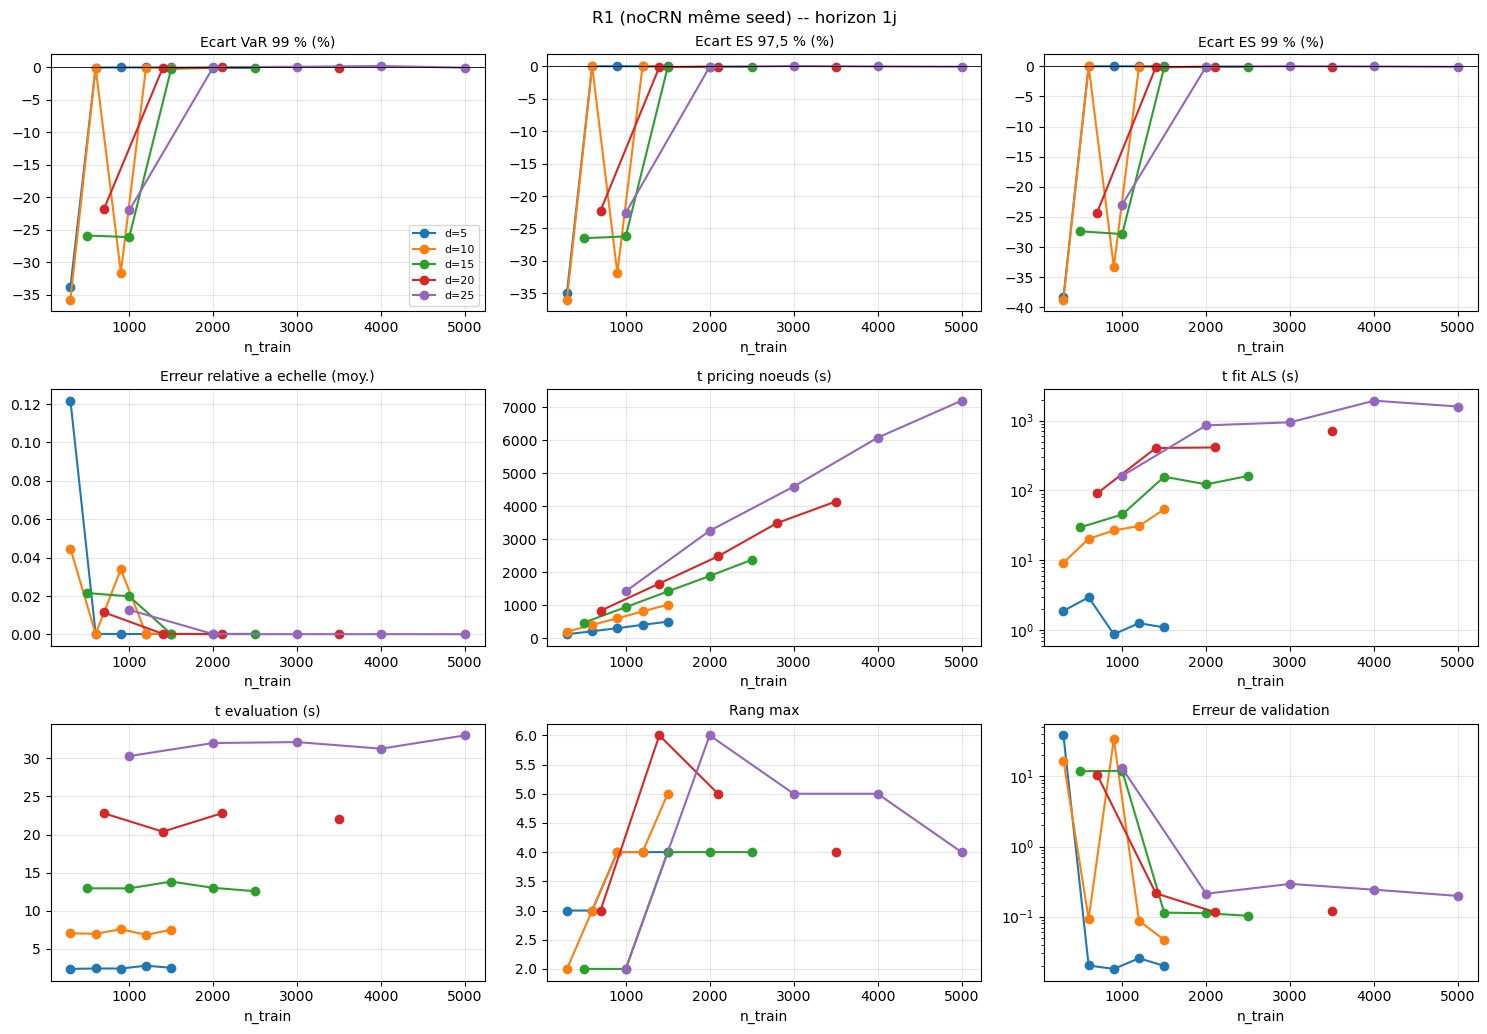

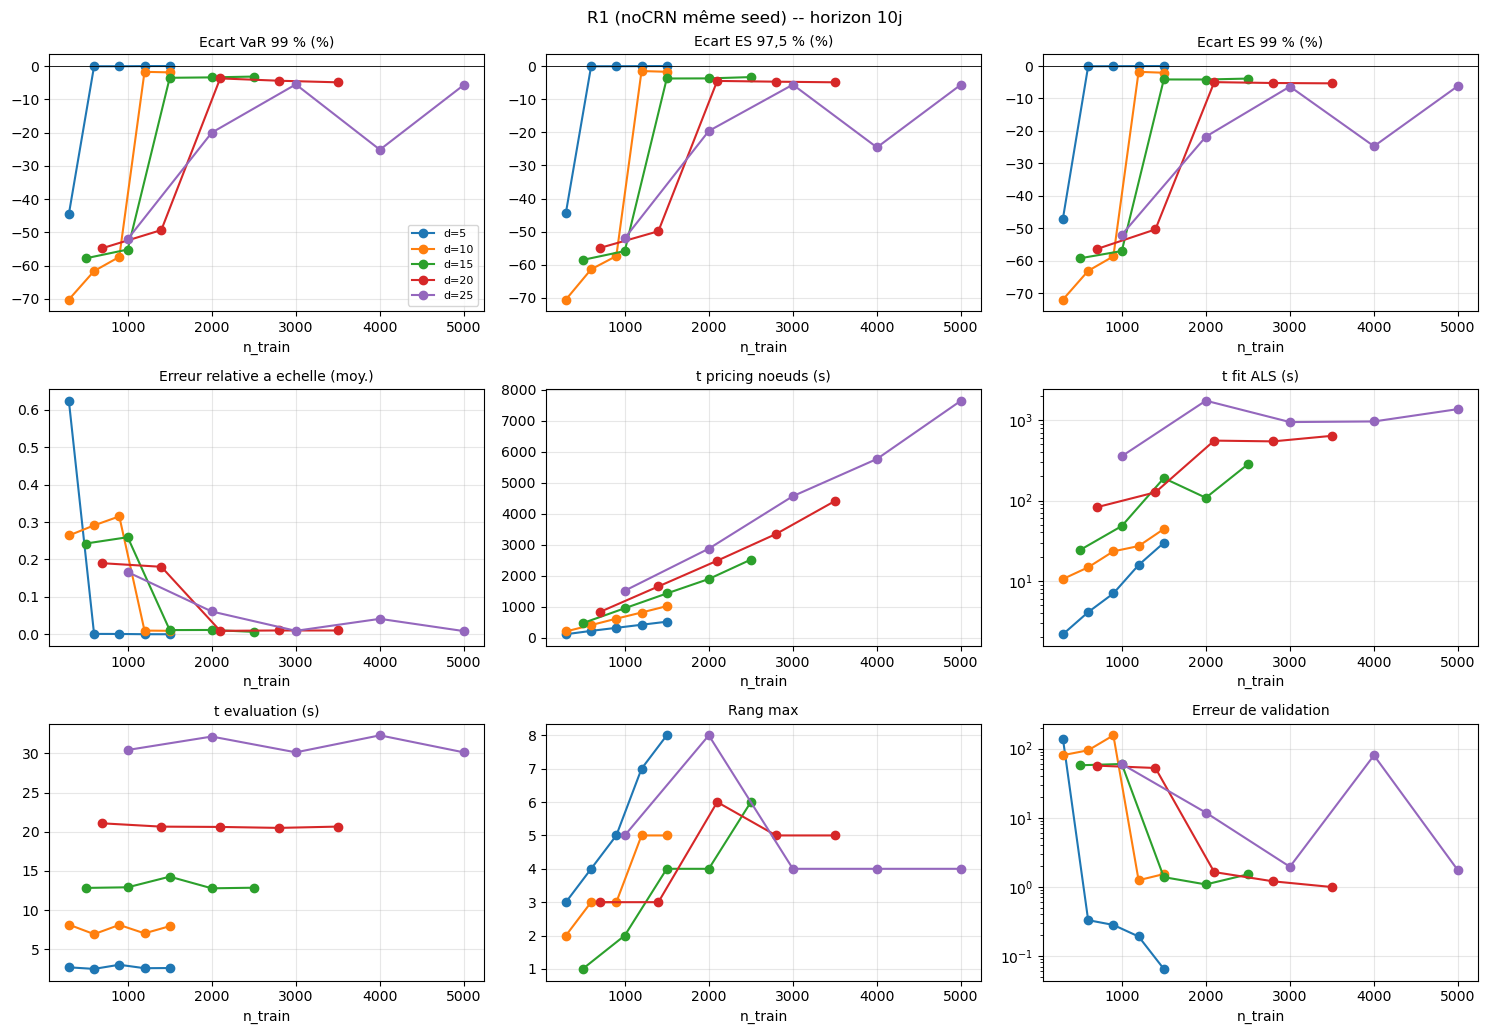

In [8]:
SW.plot_sweep(df_R1, cfg, "R1 (noCRN même seed)", root=RES_R1);

## A.4 Portefeuille : somme des 5 TT au même niveau de la grille

In [9]:
pf_R1 = SW.portfolio_table(cfg, sw, fr, S, "R1")
save_df(pf_R1.set_index(["horizon", "niveau"]), os.path.join(RES_R1, "portefeuille"))
display(pf_R1.set_index(["horizon", "niveau"]))

regime                                            n_train groupes_en_repli_FR       V0_FR    V0_proxy     t_nodes_s      t_fit_s      t_eval_s        t_FR_s  speedup_total   VaR_99_FR  VaR_99_proxy  dVaR_99_pct  ES_97_5_FR  \
horizon niveau                                                                                                                                                                                                                                  
1j      1          R1      {5: 300, 10: 300, 15: 500, 20: 700, 25: 1000}                  []  703.708571  703.071579   3058.460921   293.305634     75.395826  40215.549981      11.734358  262.740197    190.928584   -27.331796  264.175308   
        2          R1    {5: 600, 10: 600, 15: 1000, 20: 1400, 25: 2000}                  []  703.708571  704.351134   6477.745429  1329.239685     74.695447  40215.549981       5.102408  262.740197    249.592760    -5.003969  264.175308   
        3          R1    {5: 900, 10: 900, 15: 1500, 20: 2100, 25: 3000}                  []  703.708571  703.416368   9412.973326  1543.874410     78.712294  40215.549981       3.644178  262.740197    248.795906    -5.307255  264.175308   
        4          R1  {5: 1200, 10: 1200, 15: 2000, 20: 2800, 25: 4000}                [20]  703.708571  703.594826   9186.129456  2086.283887  10504.942859  40215.549981       1.846668  262.740197    262.636257    -0.039560  264.175308   
        5          R1  {5: 1500, 10: 1500, 15: 2500, 20: 3500, 25: 5000}                  []  703.708571  703.568189  15239.103629  2509.726116     77.572328  40215.549981       2.255954  262.740197    262.627155    -0.043024  264.175308   
10j     1          R1      {5: 300, 10: 300, 15: 500, 20: 700, 25: 1000}                  []  703.708571  837.403062   3108.129358   474.953090     75.215414  39887.785425      10.903373  774.412904    339.019332   -56.222407  777.342157   
        2          R1    {5: 600, 10: 600, 15: 1000, 20: 1400, 25: 2000}                  []  703.708571  759.889342   6087.589016  1939.727747     75.174754  39887.785425       4.922904  774.412904    472.828107   -38.943669  777.342157   
        3          R1    {5: 900, 10: 900, 15: 1500, 20: 2100, 25: 3000}                  []  703.708571  721.278356   9393.775352  1722.509663     76.185309  39887.785425       3.563805  774.412904    678.266111   -12.415443  777.342157   
        4          R1  {5: 1200, 10: 1200, 15: 2000, 20: 2800, 25: 4000}                  []  703.708571  701.704216  12218.615653  1657.989870     75.227516  39887.785425       2.858964  774.412904    705.981477    -8.836556  777.342157   
        5          R1  {5: 1500, 10: 1500, 15: 2500, 20: 3500, 25: 5000}                  []  703.708571  698.433940  16089.157490  2366.427841     74.228815  39887.785425       2.152627  774.412904    750.412856    -3.099128  777.342157   

                ES_97_5_proxy  dES_97_5_pct    ES_99_FR  ES_99_proxy  dES_99_pct  erel_sc_mean   bias_mean  
horizon niveau                                                                                              
1j      1          191.855574    -27.375660  304.984487   216.509693  -29.009605      0.017662    7.390728  
        2          250.563401     -5.152604  304.984487   288.263851   -5.482455      0.003689    2.159614  
        3          249.870392     -5.414933  304.984487   287.758998   -5.647989      0.004007    1.244761  
        4          264.070000     -0.039863  304.984487   304.857256   -0.041717      0.000159   -0.110511  
        5          263.967135     -0.078801  304.984487   304.703525   -0.092123      0.000191   -0.130745  
10j     1          338.274523    -56.483188  889.194650   374.217307  -57.915029      0.222915  145.124667  
        2          475.159624    -38.873812  889.194650   531.299009  -40.249415      0.117208   74.539774  
        3          676.980979    -12.910811  889.194650   769.468005  -13.464616      0.039663   22.386566  
        4          710.020657   

## A.5 Distributions des pertes au `n_train` maximal

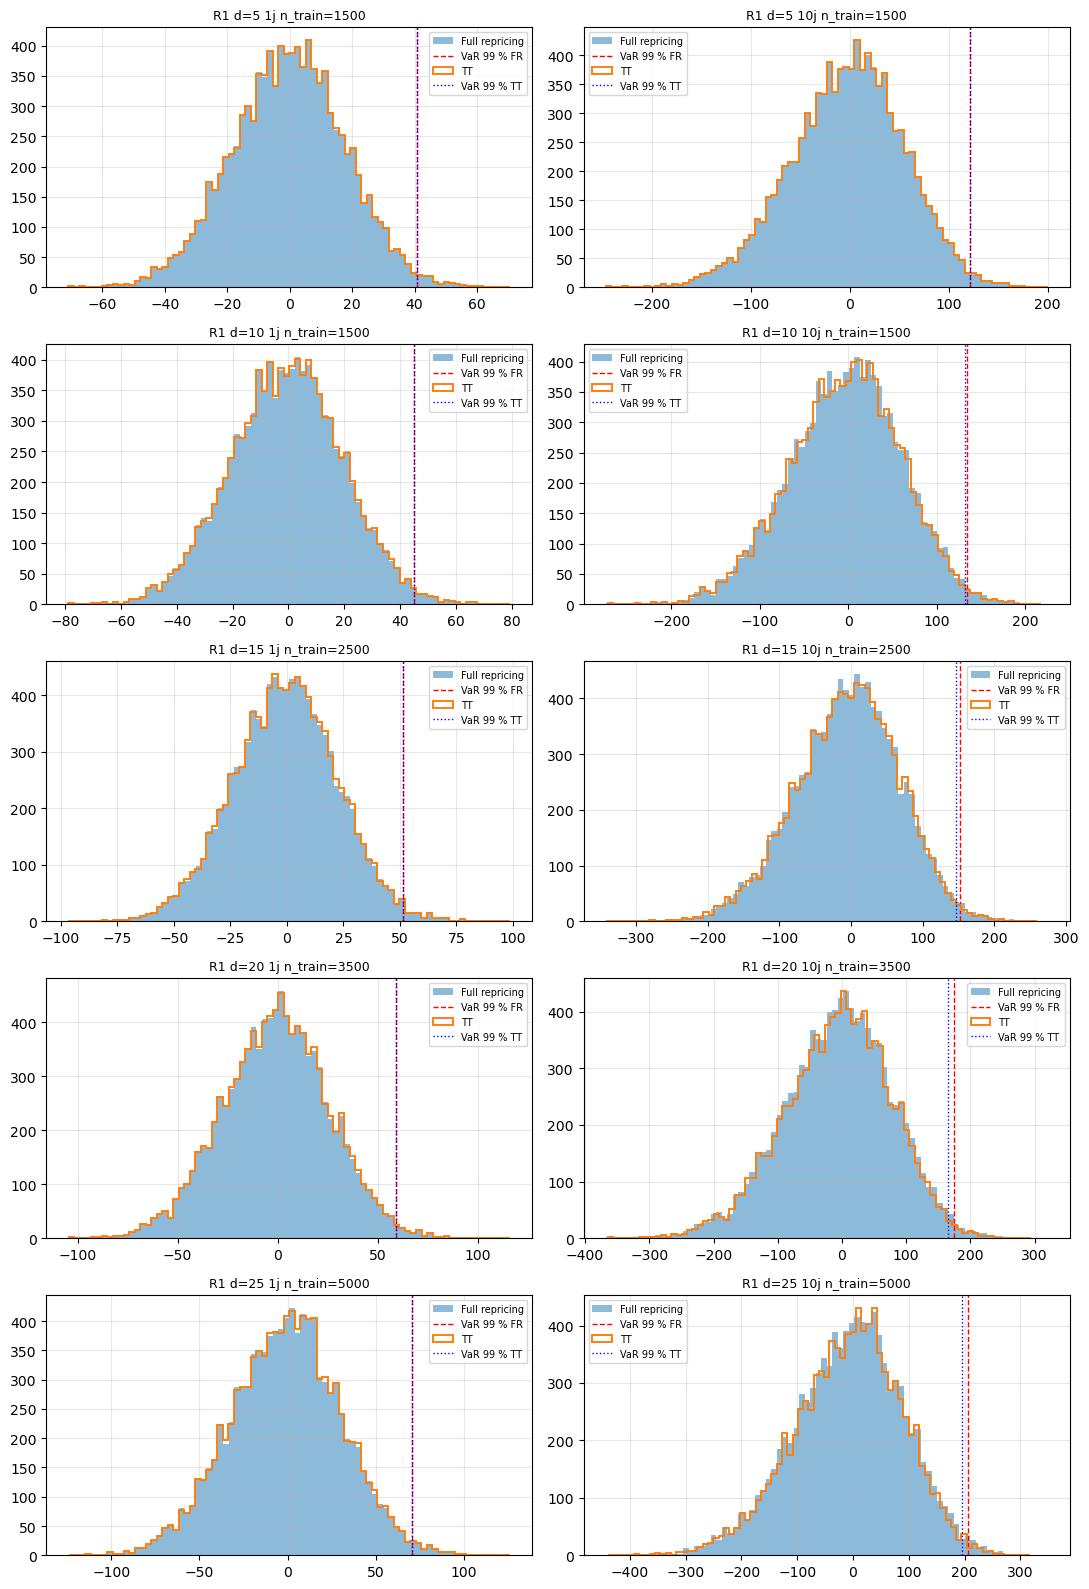

Résultats R1 écrits dans cache/sweep/results/R1


In [10]:
SW.plot_losses_max(cfg, sw, fr, S, "R1", root=RES_R1);
print("Résultats R1 écrits dans", RES_R1)

---
# Partie B — R2 : noCRN, seed différente à chaque pricing des nœuds (pricer front office)
Valeurs aux nœuds = fonction du full repricing **+ bruit Monte-Carlo propre à chaque pricing**. Colonnes `bruit_noeuds_*` : écart R2 − R1 aux mêmes nœuds (bruit effectivement injecté dans le fit).

## B.1 Construction des TT (pricing des nœuds, fit, évaluation) — caché, reprenable

In [ ]:
RUN_R2 = True       # False : lecture du cache uniquement
if RUN_R2:
    SW.run_sweep(cfg, sw, market, pf, S, me, "R2")

  R2 d=5  1j  n=300   :
    noeuds R2 : 295 noeuds x 20 produits, 3/3 paquets a calculer
      paquet 3/3  92s  ETA 0s    
    noeuds : 92s (0.311s/noeud)
    fit : 2.1s, rangs [1, 3, 1, 1, 1, 1] (max 3), val_err 3.827e+01, 60 tours de rang
  R2 d=5  1j  n=600   :
    noeuds R2 : 582 noeuds x 20 produits, 6/6 paquets a calculer
      paquet 6/6  186s  ETA 0s    
    noeuds : 184s (0.317s/noeud)
    fit : 4.3s, rangs [1, 2, 2, 2, 3, 1] (max 3), val_err 1.572e+00, 106 tours de rang
  R2 d=5  1j  n=900   :
    noeuds R2 : 851 noeuds x 20 produits, 9/9 paquets a calculer
      paquet 9/9  270s  ETA 0s     
    noeuds : 268s (0.315s/noeud)
    fit : 3.0s, rangs [1, 2, 2, 2, 2, 1] (max 2), val_err 1.432e+00, 58 tours de rang
  R2 d=5  1j  n=1200  :
    noeuds R2 : 1117 noeuds x 20 produits, 12/12 paquets a calculer
      paquet 12/12  360s  ETA 0s    
    noeuds : 358s (0.320s/noeud)
    fit : 3.1s, rangs [1, 2, 2, 2, 2, 1] (max 2), val_err 1.579e+00, 58 tours de rang
  R2 d=5  1j  n=1500  :

## B.2 Résultats par TT : temps mesurés, rangs, VaR / ES vs full repricing

In [ ]:
df_R2 = SW.sweep_table(cfg, sw, fr, S, "R2")
RES_R2 = SW.results_dir(cfg, "R2")
save_df(df_R2.set_index(["d", "horizon", "n_train"]), os.path.join(RES_R2, "par_tt"))
display(Markdown("**Synthèse**"))
cols = ["statut", "n_noeuds", "t_nodes_s", "t_noeud_moy_s", "t_fit_s", "t_eval_s",
        "rangs", "rang_max", "n_tours_rang", "val_err",
        "VaR_99_FR", "VaR_99_proxy", "dVaR_99_pct", "ES_97_5_FR", "ES_97_5_proxy",
        "dES_97_5_pct", "ES_99_FR", "ES_99_proxy", "dES_99_pct", "erel_sc_mean",
        "speedup_online", "speedup_total"] + ["bruit_noeuds_std", "bruit_noeuds_rel_std", "n_seeds_distinctes"]
display(df_R2.set_index(["d", "horizon", "n_train"])[[c for c in cols if c in df_R2]])
display(Markdown("**Tableau complet (toutes colonnes)**"))
display(df_R2.set_index(["d", "horizon", "n_train"]))

## B.3 Effet de `n_train` (courbes par groupe)

In [ ]:
SW.plot_sweep(df_R2, cfg, "R2 (noCRN seed variable)", root=RES_R2);

## B.4 Portefeuille : somme des 5 TT au même niveau de la grille

In [ ]:
pf_R2 = SW.portfolio_table(cfg, sw, fr, S, "R2")
save_df(pf_R2.set_index(["horizon", "niveau"]), os.path.join(RES_R2, "portefeuille"))
display(pf_R2.set_index(["horizon", "niveau"]))

## B.5 Distributions des pertes au `n_train` maximal

In [ ]:
SW.plot_losses_max(cfg, sw, fr, S, "R2", root=RES_R2);
print("Résultats R2 écrits dans", RES_R2)

---
# Partie C — Comparaison R1 / R2 à (d, horizon, n_train) égal

In [ ]:
df_cmp = SW.compare_regimes(df_R1, df_R2)
save_df(df_cmp, os.path.join(SW.results_dir(cfg, "comparaison"), "R1_vs_R2"))
display(df_cmp)

In [ ]:
fig, axes = plt.subplots(len(HS), 4, figsize=(18, 4 * len(HS)))
for row, h in zip(np.atleast_2d(axes), HS):
    for ax, (col, lab, log) in zip(row, [("t_fit_s", "t fit ALS (s)", True),
                                        ("dVaR_99_pct", "Écart VaR 99 % (%)", False),
                                        ("dES_99_pct", "Écart ES 99 % (%)", False),
                                        ("rang_max", "Rang max", False)]):
        for d in DIMS:
            for reg, df, ls in [("R1", df_R1, "-"), ("R2", df_R2, "--")]:
                g = df[(df.d == d) & (df.horizon == h)].sort_values("n_train")
                if col in g:
                    ax.plot(g.n_train, g[col], ls, marker="o", ms=3,
                            label="d=%d %s" % (d, reg))
        if log: ax.set_yscale("log")
        if col.endswith("_pct"): ax.axhline(0, color="k", lw=.6)
        ax.set_title("%s — %s (trait plein R1, tirets R2)" % (lab, h), fontsize=9)
        ax.set_xlabel("n_train"); ax.grid(alpha=.3)
np.atleast_2d(axes)[0, 0].legend(fontsize=6, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(SW.results_dir(cfg, "comparaison"), "R1_vs_R2.png"), dpi=110)
plt.show()